# 04 · ARIMA e a Metodologia Box-Jenkins

**PNV-3421 — Processos Estocásticos — Previsão de Demanda**
**Ementa, tópico 4:** *"ARIMA: Modelo Auto-regressivo integrado com Média Móvel. Teste de Dickey-Fuller para Séries estacionárias. Teste de Ljung-Box-Pierce. Critério de informação de Akaike. Metodologia Box-Jenkins"*

### De onde vem este material
Este notebook consolida **3 fontes redundantes** da pasta original:
* `2.1/ARIMA - Parte 1.ipynb` e `2.2/ARIMA - Parte 2.ipynb` — rascunhos de aula, com os mesmos dados e exemplos usados aqui (descartados como fonte separada: seu conteúdo já está 100% incorporado abaixo);
* `2.3/PNV3421_Aula09_ARIMA.ipynb` — a versão consolidada e com teoria completa, usada aqui como espinha dorsal (Seções 1 a 9);
* `2.4/ARIMA_Ex1.ipynb` + `Exercício1.txt` e `ARIMA_Ex2.ipynb` + `Exercício2.txt` — que, ao conferir os dados, são **exatamente os 2 exercícios finais** do notebook de `2.3` (que lá estavam sem solução): resolvemos ambos na Seção 11, combinando a leitura manual de ACF/PACF com a busca exaustiva de `(p,d,q)` e o `auto_arima`.

### Roteiro
1. Modelo Autorregressivo (AR)
2. Modelo de Média Móvel (MA)
3. Suavização exponencial x AR x MA (breve — tratamento completo no notebook `01`)
4. ARMA e estacionariedade: teste de Dickey-Fuller
5. ARIMA(p,d,q) e o papel de *d*
6. Como ler a ACF e a PACF (+ jogo de adivinhação)
7. Identificação de *p*, *q* e do melhor modelo (Exemplos 2, 3 e 4)
8. Resíduos e teste de Ljung-Box-Pierce
9. Treino, teste e previsão final
10. Mapa da Metodologia Box-Jenkins
11. Exercícios resolvidos (os 2 exercícios do curso)

In [1]:
import warnings
from statsmodels.tools.sm_exceptions import EstimationWarning, ConvergenceWarning
for categoria in (UserWarning, FutureWarning, EstimationWarning, ConvergenceWarning):
    warnings.filterwarnings('ignore', category=categoria)

import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from statsmodels.tsa.ar_model import AutoReg
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.holtwinters import SimpleExpSmoothing
from statsmodels.tsa.stattools import adfuller, acf, pacf
from statsmodels.tsa.arima_process import ArmaProcess
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox

np.set_printoptions(suppress=True, precision=4)
plt.rcParams.update({'figure.figsize': (12, 4), 'figure.dpi': 100,
                     'axes.spines.top': False, 'axes.spines.right': False})


def mse(y, f):
    y, f = np.asarray(y), np.asarray(f)
    return np.mean((y - f) ** 2)


def metricas(y, f):
    e = np.asarray(y) - np.asarray(f)
    return {'RMSE': np.sqrt(np.mean(e**2)), 'MAE': np.mean(np.abs(e)),
            'MAPE (%)': 100 * np.mean(np.abs(e / np.asarray(y)))}


def teste_adf(serie, nome='serie'):
    estat, p = adfuller(pd.Series(serie).dropna())[:2]
    conclusao = 'estacionaria (rejeita H0)' if p < 0.05 else 'NAO estacionaria (aceita H0)'
    print(f'{nome}: ADF = {estat:.3f}, p-valor = {p:.4f} -> {conclusao}')


def acf_pacf(serie, lags=20, titulo=''):
    fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
    plot_acf(serie, lags=lags, ax=ax[0]); ax[0].set_title(f'ACF {titulo}')
    plot_pacf(serie, lags=lags, ax=ax[1], method='ywm'); ax[1].set_title(f'PACF {titulo}')
    plt.tight_layout(); plt.show()

## Mapa da Metodologia Box-Jenkins (roteiro visual)

Antes de entrar nos detalhes, eis o "mapa" que vamos seguir — a mesma lógica se repete em todo exemplo deste notebook (inclusive nos exercícios da Seção 11).

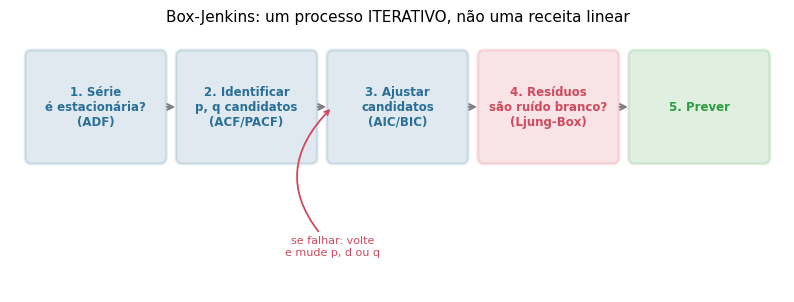

In [2]:
fig, ax = plt.subplots(figsize=(10, 3.4))
etapas = ['1. Série\né estacionária?\n(ADF)', '2. Identificar\np, q candidatos\n(ACF/PACF)',
          '3. Ajustar\ncandidatos\n(AIC/BIC)', '4. Resíduos\nsão ruído branco?\n(Ljung-Box)', '5. Prever']
cores = ['#2a6f97', '#2a6f97', '#2a6f97', '#d1495b', '#2a9d3c']
n = len(etapas)
for i, (etapa, cor) in enumerate(zip(etapas, cores)):
    x = i * 2.2
    box = mpatches.FancyBboxPatch((x, 0), 1.9, 1.1, boxstyle='round,pad=0.08',
                                   edgecolor=cor, facecolor=cor, alpha=0.15, linewidth=2)
    ax.add_patch(box)
    ax.text(x + 0.95, 0.55, etapa, ha='center', va='center', fontsize=8.5, color=cor, fontweight='bold')
    if i < n - 1:
        ax.annotate('', xy=(x + 2.15, 0.55), xytext=(x + 1.95, 0.55),
                     arrowprops=dict(arrowstyle='->', color='gray', lw=1.5))
ax.annotate('se falhar: volte\ne mude p, d ou q', xy=(4.4, 0.55), xytext=(4.4, -1.1),
            ha='center', fontsize=8, color='#d1495b',
            arrowprops=dict(arrowstyle='->', color='#d1495b', lw=1.3,
                             connectionstyle='arc3,rad=-0.5'))
ax.set_xlim(-0.3, n * 2.2); ax.set_ylim(-1.5, 1.4); ax.axis('off')
ax.set_title('Box-Jenkins: um processo ITERATIVO, não uma receita linear', fontsize=11)
plt.show()

## 1. Modelo Autorregressivo ("AR")

Um modelo autorregressivo de **p** períodos usa os próprios valores passados como variáveis explicativas:

$$\hat Y_t = \phi_0 + \phi_1 Y_{t-1} + \phi_2 Y_{t-2} + \dots + \phi_p Y_{t-p}, \qquad \epsilon_t = Y_t - \hat Y_t$$

Os coeficientes $\phi$ são obtidos por mínimos quadrados. Exemplo da aula (75 observações):

Parametros AR(2): [114.9353  -0.5289   0.0049]
Parametros AR(3): [93.3009 -0.5255  0.1101  0.1803]


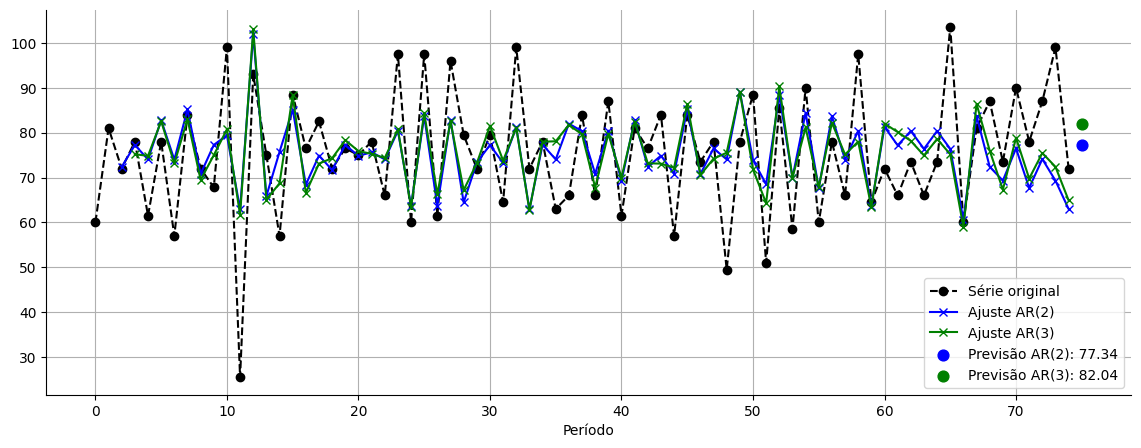

MSE AR(2) = 136.14   MSE AR(3) = 133.98


In [3]:
series = np.array([
    60, 81, 72, 78, 61.5, 78, 57, 84, 72, 67.8,
    99, 25.5, 93, 75, 57, 88.5, 76.5, 82.5, 72, 76.5,
    75, 78, 66, 97.5, 60, 97.5, 61.5, 96, 79.5, 72,
    79.5, 64.5, 99, 72, 78, 63, 66, 84, 66, 87,
    61.5, 81, 76.5, 84, 57, 84, 73.5, 78, 49.5, 78,
    88.5, 51, 85.5, 58.5, 90, 60, 78, 66, 97.5, 64.5,
    72, 66, 73.5, 66, 73.5, 103.5, 60, 81, 87, 73.5,
    90, 78, 87, 99, 72])

model_ar2 = AutoReg(series, lags=2).fit()
model_ar3 = AutoReg(series, lags=3).fit()
print('Parametros AR(2):', model_ar2.params.round(4))
print('Parametros AR(3):', model_ar3.params.round(4))

fitted_ar2 = model_ar2.predict(start=2, end=len(series) - 1)
fitted_ar3 = model_ar3.predict(start=3, end=len(series) - 1)
prev_ar2 = model_ar2.predict(start=len(series), end=len(series))[0]
prev_ar3 = model_ar3.predict(start=len(series), end=len(series))[0]

plt.figure(figsize=(14, 5))
plt.plot(series, 'ko--', label='Série original')
plt.plot(range(2, len(series)), fitted_ar2, 'b-x', label='Ajuste AR(2)')
plt.plot(range(3, len(series)), fitted_ar3, 'g-x', label='Ajuste AR(3)')
plt.scatter(len(series), prev_ar2, color='b', s=60, label=f'Previsão AR(2): {prev_ar2:.2f}')
plt.scatter(len(series), prev_ar3, color='g', s=60, label=f'Previsão AR(3): {prev_ar3:.2f}')
plt.legend(); plt.grid(True); plt.xlabel('Período'); plt.show()

mse_ar2, mse_ar3 = mse(series[2:], fitted_ar2), mse(series[3:], fitted_ar3)
print(f'MSE AR(2) = {mse_ar2:.2f}   MSE AR(3) = {mse_ar3:.2f}')

## 2. Modelo de Média Móvel ("MA")

Um modelo de média móvel de **q** períodos usa os **erros** (resíduos) passados:

$$\hat Y_t = w_0 + w_1 \epsilon_{t-1} + w_2 \epsilon_{t-2} + \dots + w_q \epsilon_{t-q}$$

No `statsmodels`, um MA(q) é um `ARIMA(order=(0, 0, q))`.

Parâmetros MA(1): [ 75.2711  -0.3984 148.4466]


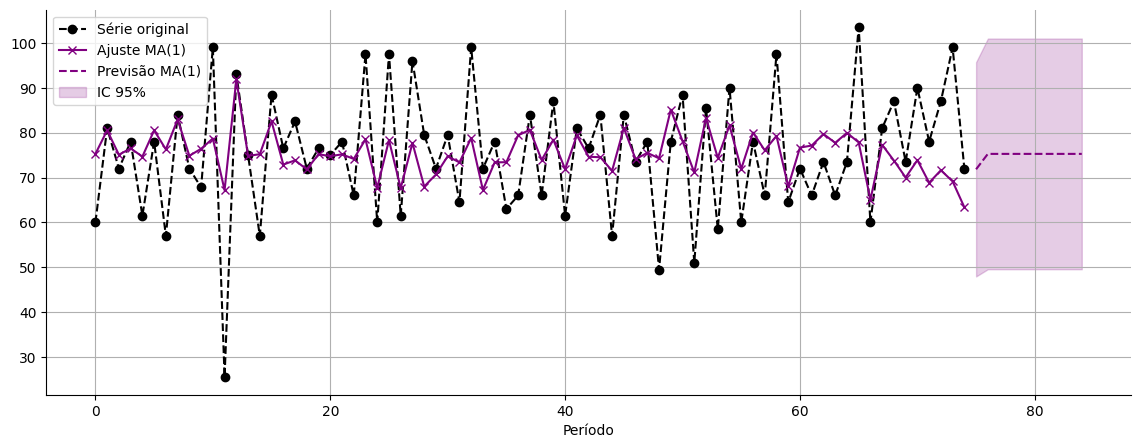

MSE MA(1) = 147.73  — note que, após 1 período, a previsão do MA(1) volta à média w0.


In [4]:
model_ma1 = ARIMA(series, order=(0, 0, 1)).fit()
print('Parâmetros MA(1):', model_ma1.params.round(4))

fitted_ma1 = model_ma1.fittedvalues
prev = model_ma1.get_forecast(steps=10)
ic = prev.conf_int(alpha=0.05)
idx = np.arange(len(series), len(series) + 10)

plt.figure(figsize=(14, 5))
plt.plot(series, 'ko--', label='Série original')
plt.plot(fitted_ma1, color='purple', marker='x', label='Ajuste MA(1)')
plt.plot(idx, prev.predicted_mean, '--', color='purple', label='Previsão MA(1)')
plt.fill_between(idx, ic[:, 0], ic[:, 1], color='purple', alpha=0.2, label='IC 95%')
plt.legend(); plt.grid(True); plt.xlabel('Período'); plt.show()

mse_ma1 = mse(series[1:], fitted_ma1[1:])
print(f'MSE MA(1) = {mse_ma1:.2f}  — note que, após 1 período, a previsão do MA(1) volta à média w0.')

## 3. Suavização Exponencial x AR x MA

*(tratamento completo de suavização exponencial, Holt e Holt-Winters: ver notebook [`01_Suavizacao_Exponencial.ipynb`](01_Suavizacao_Exponencial.ipynb))*

$$\hat Y_{t+1} = \alpha Y_t + (1-\alpha)\hat Y_t \;=\; \alpha Y_t + \alpha(1-\alpha) Y_{t-1} + \alpha(1-\alpha)^2 Y_{t-2} + \dots$$

* **≈ AR:** parece um AR de ordem infinita, mas com pesos **fixos** (positivos, decrescentes, somam 1, um só α). No AR(p) os pesos são **livres** e podem ser negativos.
* **≈ MA:** reescrevendo, $Y_{t+1} - Y_t = \epsilon_{t+1} - (1-\alpha)\epsilon_t$ — a suavização exponencial é, matematicamente, um **ARIMA(0,1,1)**, com $\theta = -(1-\alpha)$.

In [5]:
ses_otimo = SimpleExpSmoothing(series, initialization_method='estimated').fit()
arima011 = ARIMA(series, order=(0, 1, 1)).fit()
theta = arima011.params[0]
print(f"alpha ótimo da SES = {ses_otimo.params['smoothing_level']:.4f}  (perto de 0: a suavização vira a média {series.mean():.1f})")
print(f'ARIMA(0,1,1): theta = {theta:.3f}  ->  alpha equivalente = 1+theta = {1 + theta:.3f}')

tabela = pd.DataFrame({'MSE': [mse(series[1:], ses_otimo.fittedvalues[1:]), mse_ma1, mse_ar2, mse_ar3]},
                      index=['Suavização exponencial (alpha ótimo ~ 0)', 'MA(1)', 'AR(2)', 'AR(3)'])
print(tabela.round(1))
print("\nConclusão: nesta série os valores vizinhos são correlacionados NEGATIVAMENTE (zigue-zague).")
print("A suavização exponencial só sabe 'seguir o nível' (melhor ignorar tudo, alpha->0); AR/MA usam")
print("a estrutura de correlação e reduzem o erro em ~25%. Ou seja: suavização simples é um CASO")
print("PARTICULAR (pesos fixos) dentro da família ARIMA, não uma alternativa igualmente poderosa.")

alpha ótimo da SES = 0.0000  (perto de 0: a suavização vira a média 75.2)
ARIMA(0,1,1): theta = -0.997  ->  alpha equivalente = 1+theta = 0.003
                                            MSE
Suavização exponencial (alpha ótimo ~ 0)  187.7
MA(1)                                     147.7
AR(2)                                     136.1
AR(3)                                     134.0

Conclusão: nesta série os valores vizinhos são correlacionados NEGATIVAMENTE (zigue-zague).
A suavização exponencial só sabe 'seguir o nível' (melhor ignorar tudo, alpha->0); AR/MA usam
a estrutura de correlação e reduzem o erro em ~25%. Ou seja: suavização simples é um CASO
PARTICULAR (pesos fixos) dentro da família ARIMA, não uma alternativa igualmente poderosa.


## 4. ARMA e Série Estacionária

**ARMA(p,q):** $\hat Y_t = \theta_0 + \sum_{i=1}^{p}\phi_i Y_{t-i} + \sum_{i=1}^{q} w_i \epsilon_{t-i}$

AR, MA e ARMA supõem série **estacionária** (média e variância constantes). Verificamos com o **teste de Dickey-Fuller** (H0: série NÃO estacionária):

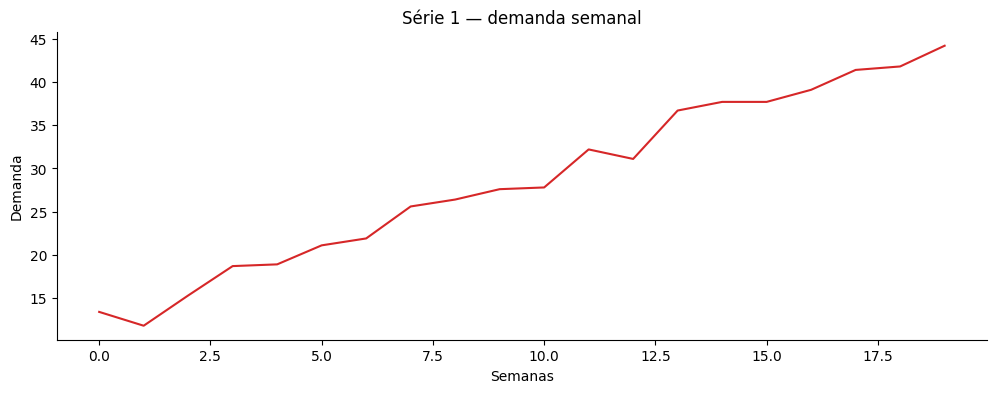

Série original: ADF = 8.681, p-valor = 1.0000 -> NAO estacionaria (aceita H0)


In [6]:
data1 = [13.4, 11.8, 15.3, 18.7, 18.9, 21.1, 21.9, 25.6, 26.4, 27.6,
         27.8, 32.2, 31.1, 36.7, 37.7, 37.7, 39.1, 41.4, 41.8, 44.2]
df1 = pd.DataFrame({'Yt': data1})

plt.plot(df1.index, df1.Yt, color='tab:red')
plt.gca().set(title='Série 1 — demanda semanal', xlabel='Semanas', ylabel='Demanda'); plt.show()
teste_adf(df1.Yt, 'Série original')

Duas formas de torná-la estacionária:
* **Detrending:** remover a tendência ajustada por regressão;
* **Differencing:** $Y_t - Y_{t-1}$ (repetir *d* vezes se necessário).

Tendência por mínimos quadrados: Y = 10.70 + 1.70 t


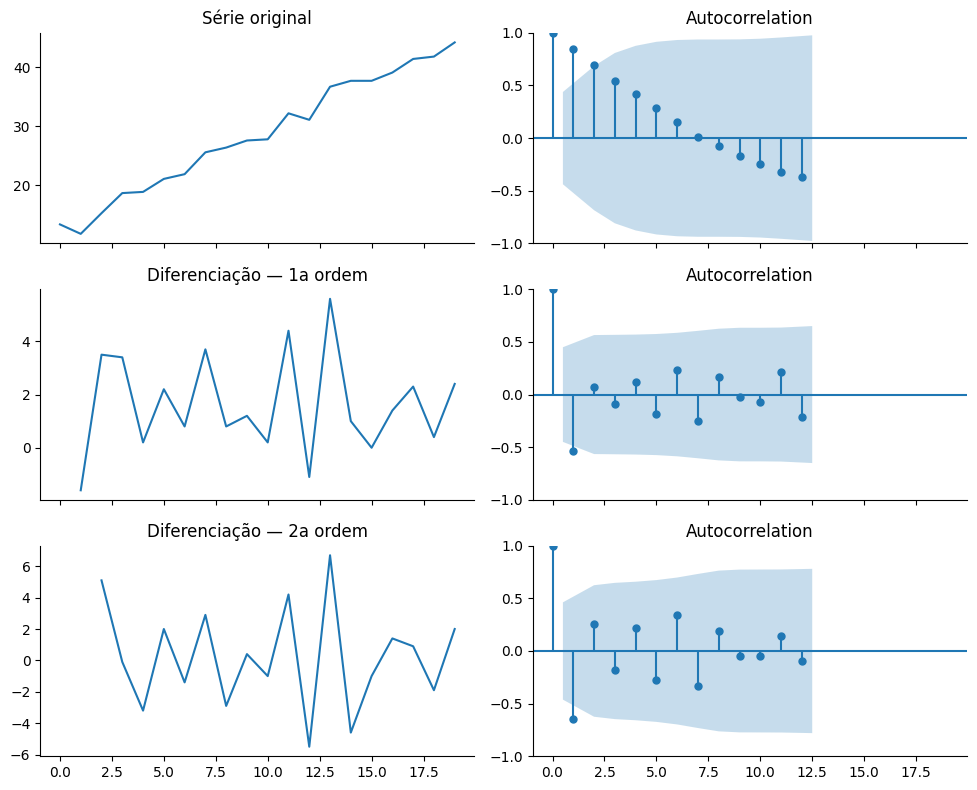

Sem tendência (detrending): ADF = -4.144, p-valor = 0.0008 -> estacionaria (rejeita H0)
1a diferença: ADF = -2.993, p-valor = 0.0355 -> estacionaria (rejeita H0)


In [7]:
t = np.arange(1, len(df1) + 1)
b1, b0 = np.polyfit(t, df1.Yt, 1)
print(f'Tendência por mínimos quadrados: Y = {b0:.2f} + {b1:.2f} t')
sem_tendencia = df1.Yt - 1.78 * t

fig, axes = plt.subplots(3, 2, figsize=(10, 8), sharex=True)
for i, (s, nome) in enumerate([(df1.Yt, 'Série original'),
                               (df1.Yt.diff(), 'Diferenciação — 1a ordem'),
                               (df1.Yt.diff().diff(), 'Diferenciação — 2a ordem')]):
    axes[i, 0].plot(s); axes[i, 0].set_title(nome)
    plot_acf(s.dropna(), ax=axes[i, 1], lags=12)
plt.tight_layout(); plt.show()

teste_adf(sem_tendencia, 'Sem tendência (detrending)')
teste_adf(df1.Yt.diff(), '1a diferença')

> **Cuidado com amostras pequenas:** com só 20 observações, o ADF com escolha automática de defasagens é instável. Use-o sempre junto com o gráfico e a ACF, nunca isoladamente.

## 5. ARIMA(p,d,q) e o papel de *d*

No ARIMA, os termos AR e MA se aplicam à série **diferenciada *d* vezes**, $W_t$:

* $d=0$: $W_t = Y_t$   $d=1$: $W_t = Y_t - Y_{t-1}$   $d=2$: $W_t = (Y_t-Y_{t-1})-(Y_{t-1}-Y_{t-2})$

$$\hat W_t = \theta_0 + \sum \phi_i W_{t-i} + \sum w_i \epsilon_{t-i}$$

A previsão em nível é obtida "integrando" de volta: $\hat Y_t = Y_{t-1} + \hat W_t$. No `statsmodels`, basta passar a série original com `order=(p, d, q)`.

## 6. Como ler a ACF e a PACF

* **ACF(k):** correlação entre $Y_t$ e $Y_{t-k}$. **PACF(k):** a mesma correlação, descontado o efeito das defasagens intermediárias.
* Faixa azul: intervalo de 95% sob correlação nula (≈ ±1,96/√n). Barra dentro da faixa → não significativa.

| | AR(p) | MA(q) | ARMA(p,q) |
|---|---|---|---|
| **ACF** | decai | **corta após q** | decai |
| **PACF** | **corta após p** | decai | decai |

**Por quê?** No AR(1), $Y_t$ depende diretamente só de $Y_{t-1}$; a correlação com defasagens maiores é indireta e se dilui (ACF = $\phi^k$). A PACF remove os efeitos indiretos → zero após *p*. No MA(1), $Y_t$ e $Y_{t-2}$ não compartilham nenhum choque $\epsilon$ → ACF zero após *q*.

### Jogo de adivinhação — veja a ACF/PACF e tente identificar o modelo ANTES de revelar

Olhe os 2 pares de gráficos abaixo (A e B) e tente adivinhar: qual é AR(1) e qual é MA(1)?
(Dica: olhe onde a PACF 'corta' e onde a ACF 'corta'.)


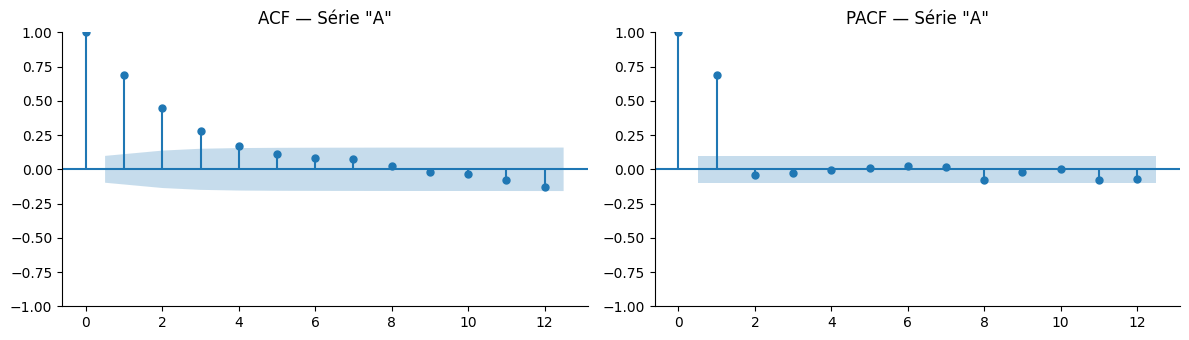

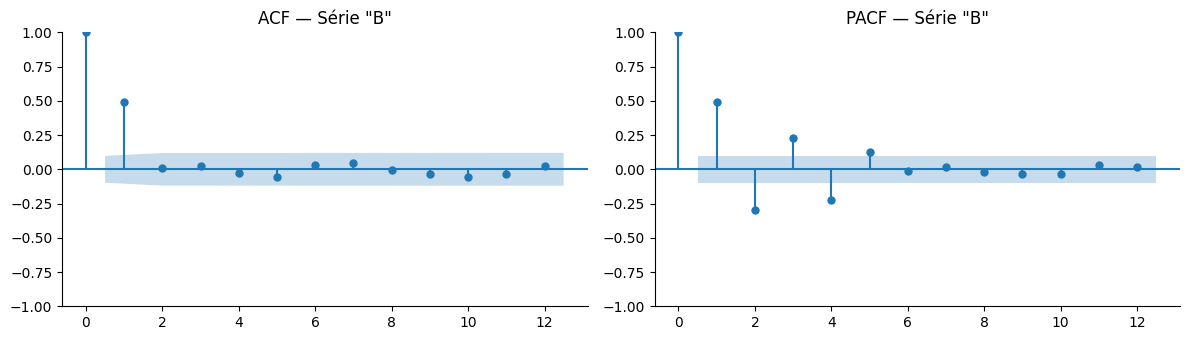

In [8]:
np.random.seed(27)
ar1 = ArmaProcess([1, -0.7], [1]).generate_sample(400)   # Y_t = 0,7 Y_{t-1} + e_t
ma1 = ArmaProcess([1], [1, 0.7]).generate_sample(400)    # Y_t = e_t + 0,7 e_{t-1}

print("Olhe os 2 pares de gráficos abaixo (A e B) e tente adivinhar: qual é AR(1) e qual é MA(1)?")
print("(Dica: olhe onde a PACF 'corta' e onde a ACF 'corta'.)")
acf_pacf(ar1, lags=12, titulo='— Série "A"')
acf_pacf(ma1, lags=12, titulo='— Série "B"')

In [9]:
print("Resposta: Série 'A' tem PACF que corta após a defasagem 1 e ACF que decai -> é o AR(1).")
print("          Série 'B' tem ACF que corta após a defasagem 1 e PACF que decai -> é o MA(1).")
print("\nExperimente: troque os coeficientes (ex. [1, -0.5, -0.3] para um AR(2)) e veja onde a PACF corta.")
print("Com amostras finitas, uma barra isolada pode sair da faixa por acaso (~1 em 20): observe o PADRÃO, não uma barra isolada.")

Resposta: Série 'A' tem PACF que corta após a defasagem 1 e ACF que decai -> é o AR(1).
          Série 'B' tem ACF que corta após a defasagem 1 e PACF que decai -> é o MA(1).

Experimente: troque os coeficientes (ex. [1, -0.5, -0.3] para um AR(2)) e veja onde a PACF corta.
Com amostras finitas, uma barra isolada pode sair da faixa por acaso (~1 em 20): observe o PADRÃO, não uma barra isolada.


## 7. Identificação de *p*, *q* e do melhor modelo (Exemplos 2, 3 e 4)

### Exemplo 2 — determinar *p*

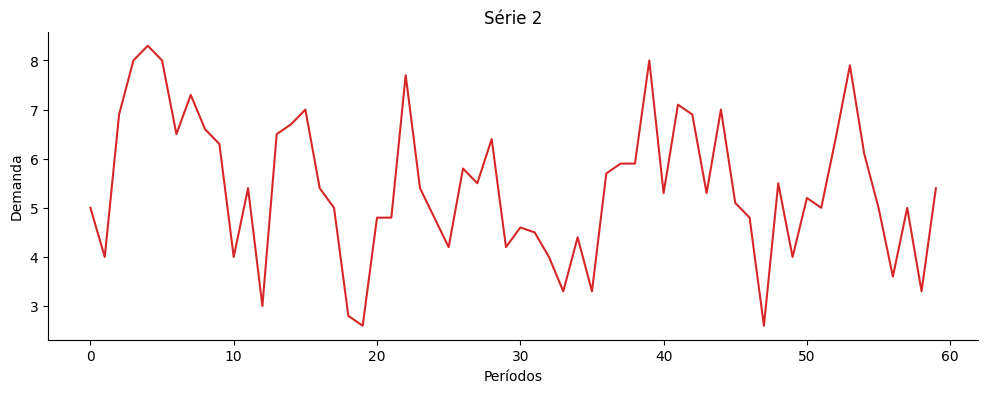

Série 2: ADF = -4.147, p-valor = 0.0008 -> estacionaria (rejeita H0)
Tente adivinhar p antes de ver a PACF revelada abaixo...


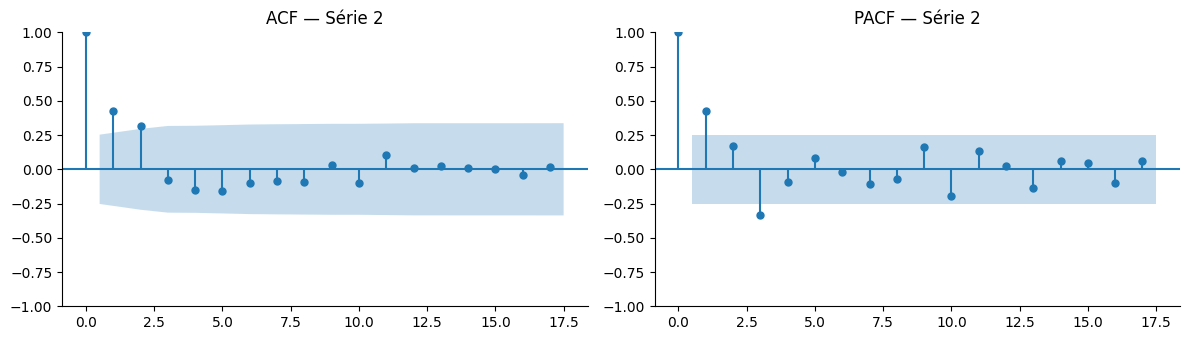

In [10]:
data2 = [5, 4, 6.9, 8, 8.3, 8, 6.5, 7.3, 6.6, 6.3,
         4, 5.4, 3, 6.5, 6.7, 7, 5.4, 5, 2.8, 2.6,
         4.8, 4.8, 7.7, 5.4, 4.8, 4.2, 5.8, 5.5, 6.4, 4.2,
         4.6, 4.5, 4, 3.3, 4.4, 3.3, 5.7, 5.9, 5.9, 8,
         5.3, 7.1, 6.9, 5.3, 7, 5.1, 4.8, 2.6, 5.5, 4,
         5.2, 5, 6.4, 7.9, 6.1, 5, 3.6, 5, 3.3, 5.4]
df2 = pd.DataFrame({'Yt': data2})

plt.plot(df2.index, df2.Yt, color='tab:red')
plt.gca().set(title='Série 2', xlabel='Períodos', ylabel='Demanda'); plt.show()
teste_adf(df2.Yt, 'Série 2')
print("Tente adivinhar p antes de ver a PACF revelada abaixo...")
acf_pacf(df2.Yt, lags=17, titulo='— Série 2')

In [11]:
# PACF significativa até a defasagem 3 -> AR(3)
ar3_ex2 = AutoReg(df2.Yt, lags=3).fit()
c = ar3_ex2.params.values
print(f'Y = {c[0]:.2f} + {c[1]:.2f} Y(t-1) + {c[2]:.2f} Y(t-2) + {c[3]:.2f} Y(t-3)')

Y = 3.37 + 0.43 Y(t-1) + 0.30 Y(t-2) + -0.36 Y(t-3)


### Exemplo 3 — determinar *q*

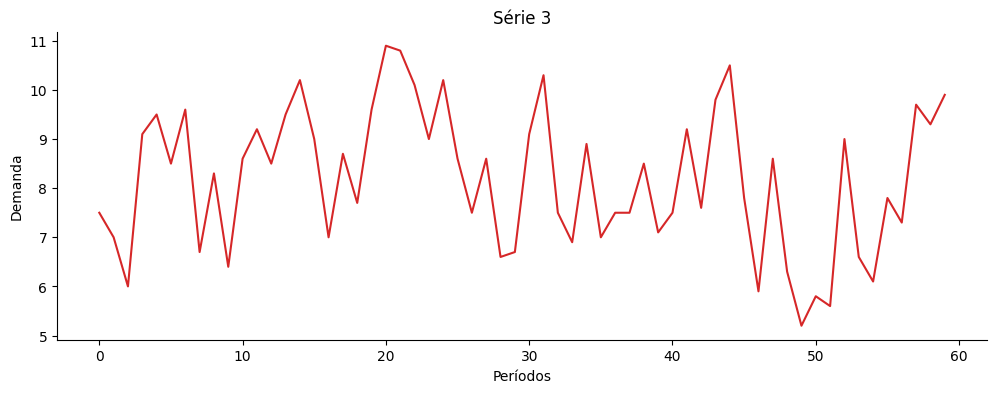

Série 3: ADF = -4.984, p-valor = 0.0000 -> estacionaria (rejeita H0)


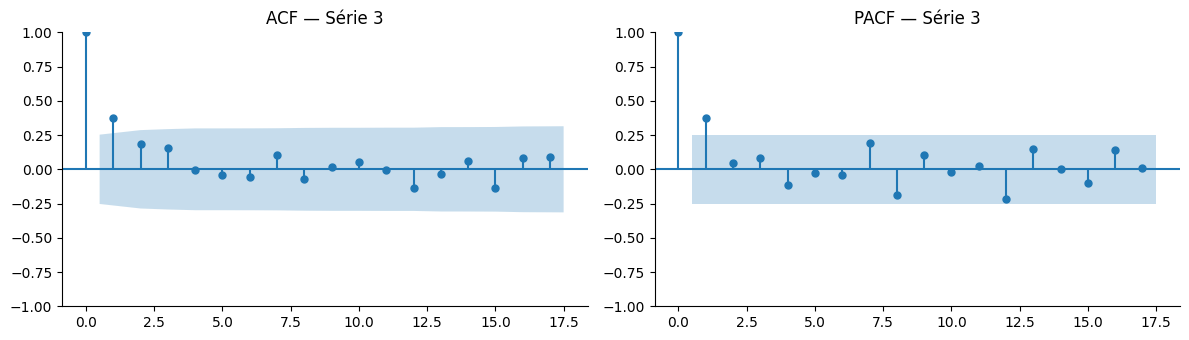

In [12]:
data3 = [7.5, 7, 6, 9.1, 9.5, 8.5, 9.6, 6.7, 8.3, 6.4,
         8.6, 9.2, 8.5, 9.5, 10.2, 9, 7, 8.7, 7.7, 9.6,
         10.9, 10.8, 10.1, 9, 10.2, 8.6, 7.5, 8.6, 6.6, 6.7,
         9.1, 10.3, 7.5, 6.9, 8.9, 7, 7.5, 7.5, 8.5, 7.1,
         7.5, 9.2, 7.6, 9.8, 10.5, 7.8, 5.9, 8.6, 6.3, 5.2,
         5.8, 5.6, 9, 6.6, 6.1, 7.8, 7.3, 9.7, 9.3, 9.9]
df3 = pd.DataFrame({'Yt': data3})

plt.plot(df3.index, df3.Yt, color='tab:red')
plt.gca().set(title='Série 3', xlabel='Períodos', ylabel='Demanda'); plt.show()
teste_adf(df3.Yt, 'Série 3')
acf_pacf(df3.Yt, lags=17, titulo='— Série 3')

In [13]:
# ACF significativa só na defasagem 1 -> MA(1)
ma1_ex3 = ARIMA(df3.Yt, order=(0, 0, 1)).fit()
print(f"Y = {ma1_ex3.params['const']:.4f} + {ma1_ex3.params['ma.L1']:.4f} e(t-1)")

Y = 8.1957 + 0.3523 e(t-1)


### Exemplo 4 — determinar o melhor modelo ARIMA (Box-Jenkins completo)

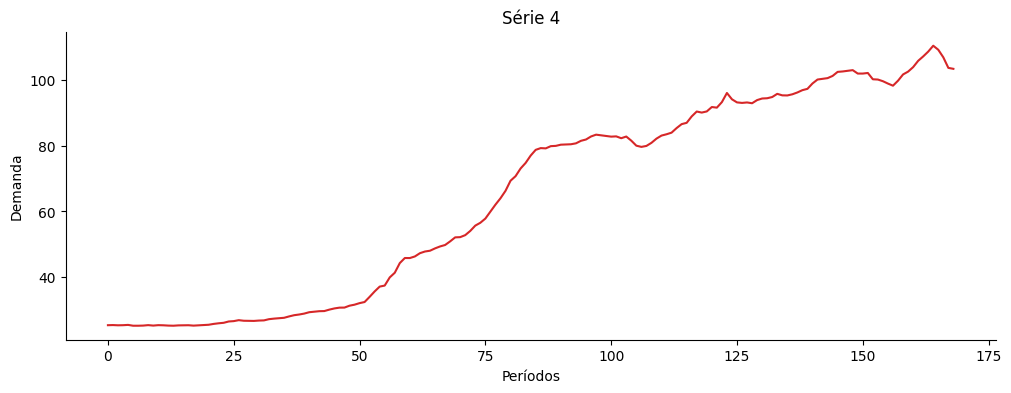

Série 4: ADF = -0.775, p-valor = 0.8265 -> NAO estacionaria (aceita H0)


In [14]:
data4 = [25.4, 25.44, 25.37, 25.4, 25.49, 25.24, 25.24, 25.28, 25.42, 25.28,
         25.41, 25.37, 25.28, 25.24, 25.34, 25.36, 25.39, 25.27, 25.35, 25.42,
         25.53, 25.79, 25.98, 26.13, 26.53, 26.64, 26.93, 26.75, 26.74, 26.7,
         26.81, 26.86, 27.23, 27.4, 27.51, 27.65, 28.07, 28.44, 28.65, 28.93,
         29.35, 29.49, 29.66, 29.7, 30.14, 30.5, 30.74, 30.76, 31.33, 31.64,
         32.11, 32.45, 34.02, 35.67, 37.14, 37.46, 39.94, 41.36, 44.3, 45.84,
         45.83, 46.32, 47.31, 47.82, 48.06, 48.77, 49.36, 49.8, 50.9, 52.12,
         52.19, 52.8, 54.08, 55.7, 56.56, 57.84, 59.94, 62.07, 64.01, 66.27,
         69.35, 70.74, 73.08, 74.77, 77, 78.75, 79.28, 79.2, 79.87, 79.96,
         80.32, 80.4, 80.45, 80.73, 81.5, 81.9, 82.82, 83.37, 83.17, 82.96,
         82.77, 82.85, 82.29, 82.8, 81.54, 80.02, 79.65, 79.94, 80.88, 82.16,
         83.09, 83.49, 83.98, 85.37, 86.57, 86.97, 88.92, 90.41, 90.09, 90.44,
         91.78, 91.59, 93.27, 96.05, 94.13, 93.19, 93.03, 93.17, 92.93, 93.89,
         94.37, 94.45, 94.82, 95.79, 95.33, 95.3, 95.65, 96.21, 96.91, 97.31,
         98.94, 100.14, 100.35, 100.57, 101.24, 102.47, 102.6, 102.81, 103, 101.96,
         101.96, 102.14, 100.22, 100.14, 99.63, 98.91, 98.27, 99.79, 101.69, 102.55,
         103.91, 105.83, 107.17, 108.64, 110.43, 109.2, 106.9, 103.69, 103.4]
df4 = pd.DataFrame({'Yt': data4})

plt.plot(df4.index, df4.Yt, color='tab:red')
plt.gca().set(title='Série 4', xlabel='Períodos', ylabel='Demanda'); plt.show()
teste_adf(df4.Yt, 'Série 4')

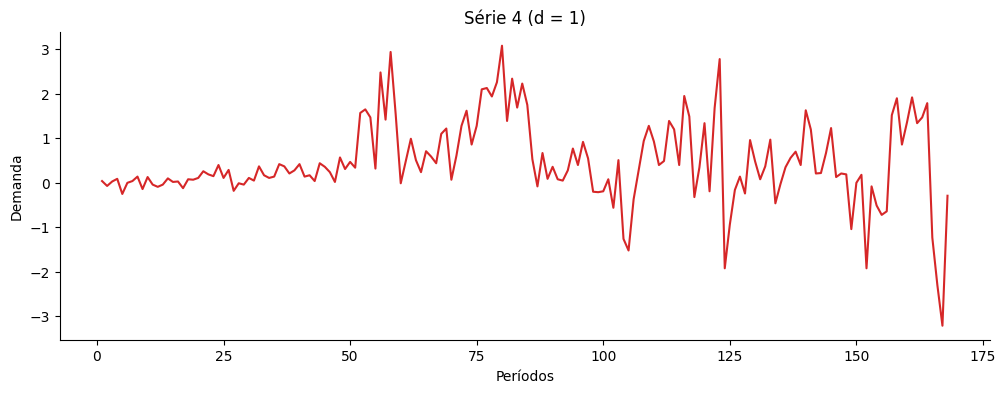

Série 4, 1a diferença: ADF = -4.048, p-valor = 0.0012 -> estacionaria (rejeita H0)


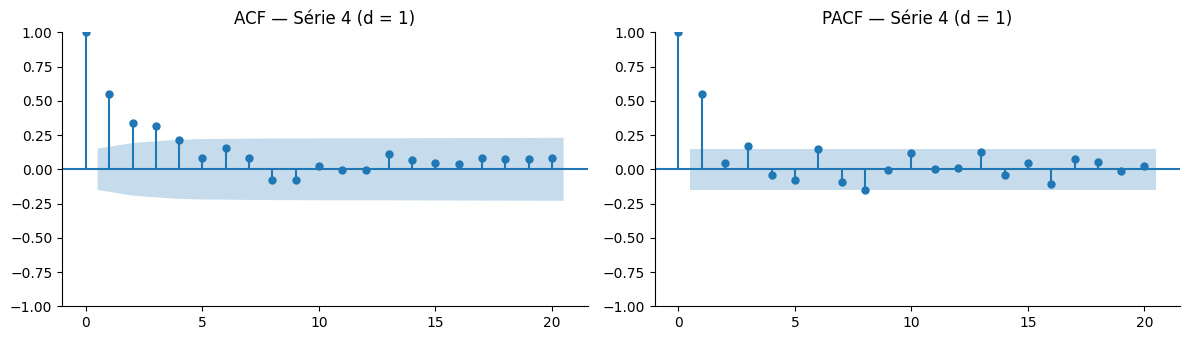

In [15]:
plt.plot(df4.Yt.diff(), color='tab:red')
plt.gca().set(title='Série 4 (d = 1)', xlabel='Períodos', ylabel='Demanda'); plt.show()
teste_adf(df4.Yt.diff(), 'Série 4, 1a diferença')
acf_pacf(df4.Yt.diff().dropna(), lags=20, titulo='— Série 4 (d = 1)')

**Metodologia Box-Jenkins (ver "mapa" no início do notebook):** processo iterativo. Testa-se a estacionariedade (Dickey-Fuller), ajustam-se candidatos (*p, d, q*), comparam-se **AIC**/BIC (menor é melhor) e verifica-se a consistência dos resíduos (**Ljung-Box-Pierce**). Se houver falhas, repete-se variando *p*, *d* e *q*.

In [16]:
ordens = [(1,1,0), (0,1,1), (1,1,1), (2,1,0), (2,1,1), (2,1,2)]
linhas = []
for o in ordens:
    fit = ARIMA(df4.Yt, order=o, trend='t').fit()
    linhas.append({'modelo': f'ARIMA{o}', 'AIC': fit.aic, 'BIC': fit.bic})
resumo = pd.DataFrame(linhas).set_index('modelo')
print(resumo.round(2))
print("\n-> Menor AIC/BIC: ARIMA(1,1,0) — modelo escolhido.")

                   AIC     BIC
modelo                        
ARIMA(1, 1, 0)  392.79  402.16
ARIMA(0, 1, 1)  404.99  414.36
ARIMA(1, 1, 1)  393.17  405.67
ARIMA(2, 1, 0)  394.15  406.65
ARIMA(2, 1, 1)  394.36  409.98
ARIMA(2, 1, 2)  394.29  413.03

-> Menor AIC/BIC: ARIMA(1,1,0) — modelo escolhido.


In [17]:
model_fit = ARIMA(df4.Yt, order=(1, 1, 0), trend='t').fit()
print(model_fit.summary())

                               SARIMAX Results                                
Dep. Variable:                     Yt   No. Observations:                  169
Model:                 ARIMA(1, 1, 0)   Log Likelihood                -193.395
Date:                Mon, 26 Oct 2026   AIC                            392.789
Time:                        20:26:50   BIC                            402.161
Sample:                             0   HQIC                           396.593
                                - 169                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
x1             0.4558      0.139      3.279      0.001       0.183       0.728
ar.L1          0.5522      0.044     12.568      0.000       0.466       0.638
sigma2         0.5841      0.041     14.222      0.0

## 8. Resíduos do Modelo e Teste de Ljung-Box-Pierce

Um bom modelo deixa resíduos sem estrutura: média ≈ 0, sem autocorrelação, aproximadamente normais.

> Com d=1, o **primeiro resíduo** do `statsmodels` é um artefato (o próprio $Y_0$) e deve ser descartado.

$$Q_m = n(n+2)\sum_{k=1}^{m}\frac{r_k^2}{n-k}, \qquad \text{rejeitar o modelo se } Q_m > \chi^2_{\alpha,\;m-p-q}$$

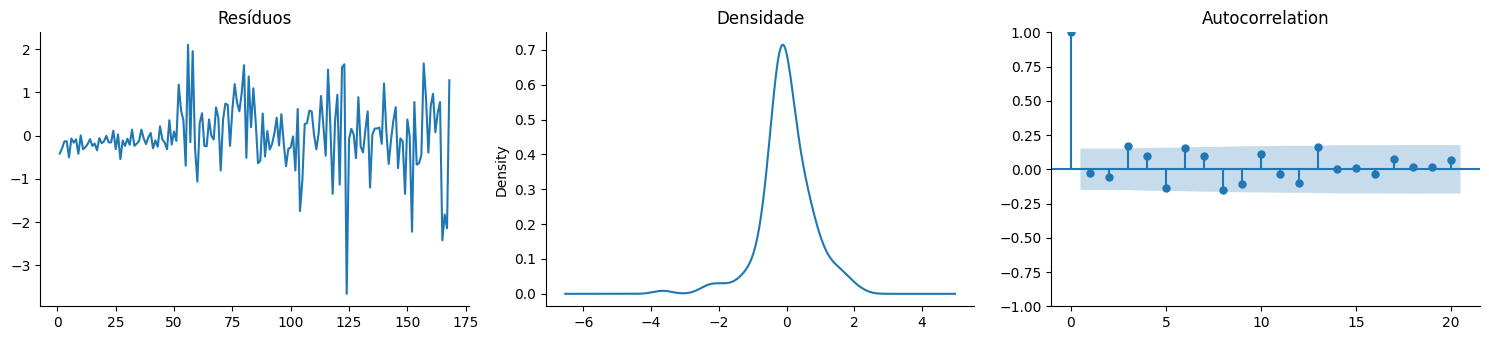

    lb_stat  lb_pvalue
5   10.4206     0.0339
10  24.7596     0.0032
15  31.7509     0.0043
20  33.9883     0.0184

p-valor < alpha -> rejeita H0 (há autocorrelação nos resíduos).
Leitura: a 1%, o modelo passa em m=5 e 20, mas não em m=10 e 15; a 5%, é rejeitado em todos.
Os resíduos têm variância crescente — uma alternativa é modelar o LOGARITMO da série:
    lb_stat  lb_pvalue
10  14.7808     0.0635
20  20.2058     0.3214


In [18]:
residuals = model_fit.resid[1:]

fig, ax = plt.subplots(1, 3, figsize=(15, 3.5))
residuals.plot(ax=ax[0], title='Resíduos')
residuals.plot(kind='kde', ax=ax[1], title='Densidade')
plot_acf(residuals, ax=ax[2], lags=20)
plt.tight_layout(); plt.show()

lb = acorr_ljungbox(residuals, lags=[5, 10, 15, 20], model_df=1)
print(lb.round(4))
print("\np-valor < alpha -> rejeita H0 (há autocorrelação nos resíduos).")
print("Leitura: a 1%, o modelo passa em m=5 e 20, mas não em m=10 e 15; a 5%, é rejeitado em todos.")
print("Os resíduos têm variância crescente — uma alternativa é modelar o LOGARITMO da série:")

fit_log = ARIMA(np.log(df4.Yt), order=(1, 1, 1), trend='t').fit()
print(acorr_ljungbox(fit_log.resid[1:], lags=[10, 20], model_df=2).round(4))

## 9. Treino, Teste e Previsão Final

AIC/BIC e resíduos medem o ajuste ao **passado**. Só um período de **teste**, reservado e não usado no ajuste, mostra se o modelo prevê bem.

* Divisão **cronológica** (nunca embaralhar): treino = início, teste = final.
* **Previsão de h passos:** prevê todo o teste de uma vez.
* **Previsão rolante de 1 passo** (*walk-forward*): a cada período incorpora o valor real e prevê o seguinte.
* Comparar sempre com o modelo **ingênuo** ($\hat Y_{t+1}=Y_t$).

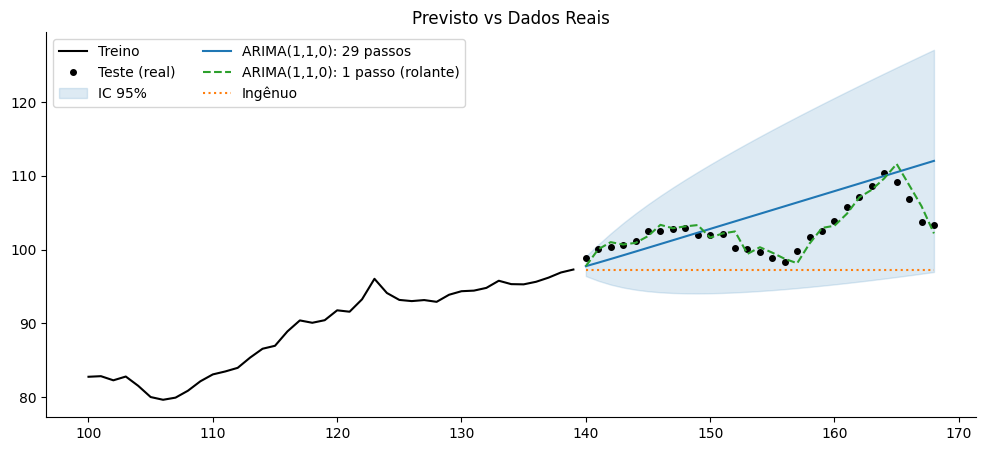

          29 passos  1 passo (rolante)  Ingênuo (29 passos)
RMSE           3.99               1.07                 6.25
MAE            3.18               0.83                 5.40
MAPE (%)       3.12               0.81                 5.17

Conclusões: todos os ARIMA superam o ingênuo; o erro cresce com o horizonte;
o menor AIC não garante o menor erro no teste — entre modelos equivalentes, prefira o mais simples.


In [19]:
train, test = df4.Yt[:140], df4.Yt[140:]
model = ARIMA(train, order=(1, 1, 0), trend='t').fit()

prev = model.get_forecast(steps=len(test))
fc, ic = prev.predicted_mean, prev.conf_int(alpha=0.05)

res, one = model, []
for y in test:
    one.append(res.forecast(1).iloc[0])
    res = res.append([y])
one = pd.Series(one, index=test.index)
ingenuo = pd.Series(train.iloc[-1], index=test.index)

plt.figure(figsize=(12, 5))
plt.plot(train[100:], color='k', label='Treino')
plt.plot(test, 'ko', ms=4, label='Teste (real)')
plt.fill_between(test.index, ic.iloc[:, 0], ic.iloc[:, 1], color='tab:blue', alpha=0.15, label='IC 95%')
plt.plot(fc, color='tab:blue', label='ARIMA(1,1,0): 29 passos')
plt.plot(one, '--', color='tab:green', label='ARIMA(1,1,0): 1 passo (rolante)')
plt.plot(ingenuo, ':', color='tab:orange', label='Ingênuo')
plt.legend(ncol=2); plt.title('Previsto vs Dados Reais'); plt.show()

print(pd.DataFrame({'29 passos': metricas(test, fc), '1 passo (rolante)': metricas(test, one),
                    'Ingênuo (29 passos)': metricas(test, ingenuo)}).round(2))
print("\nConclusões: todos os ARIMA superam o ingênuo; o erro cresce com o horizonte;")
print("o menor AIC não garante o menor erro no teste — entre modelos equivalentes, prefira o mais simples.")

     previsão  lower Yt  upper Yt
169    103.44    101.95    104.94
170    103.67    100.91    106.44
171    104.00    100.08    107.93
172    104.39     99.43    109.35
173    104.81     98.92    110.69
174    105.24     98.52    111.97
175    105.69     98.20    113.17
176    106.13     97.94    114.32
177    106.59     97.75    115.43
178    107.04     97.59    116.49


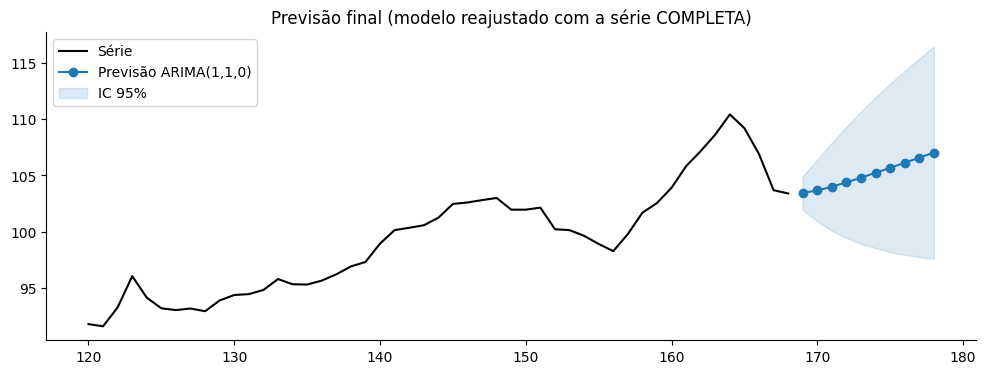

In [20]:
final = ARIMA(df4.Yt, order=(1, 1, 0), trend='t').fit()
prev = final.get_forecast(steps=10)
tab = pd.concat([prev.predicted_mean.rename('previsão'), prev.conf_int(alpha=0.05)], axis=1)
print(tab.round(2))

plt.plot(df4.Yt[120:], color='k', label='Série')
plt.plot(tab['previsão'], 'o-', color='tab:blue', label='Previsão ARIMA(1,1,0)')
plt.fill_between(tab.index, tab.iloc[:, 1], tab.iloc[:, 2], color='tab:blue', alpha=0.15, label='IC 95%')
plt.legend(); plt.title('Previsão final (modelo reajustado com a série COMPLETA)'); plt.show()

## 10. Tabela-cola: ACF/PACF por tipo de modelo

Recapitulando visualmente — compare a PACF de 3 processos AR(2) com coeficientes diferentes, para fixar onde cada um "corta":

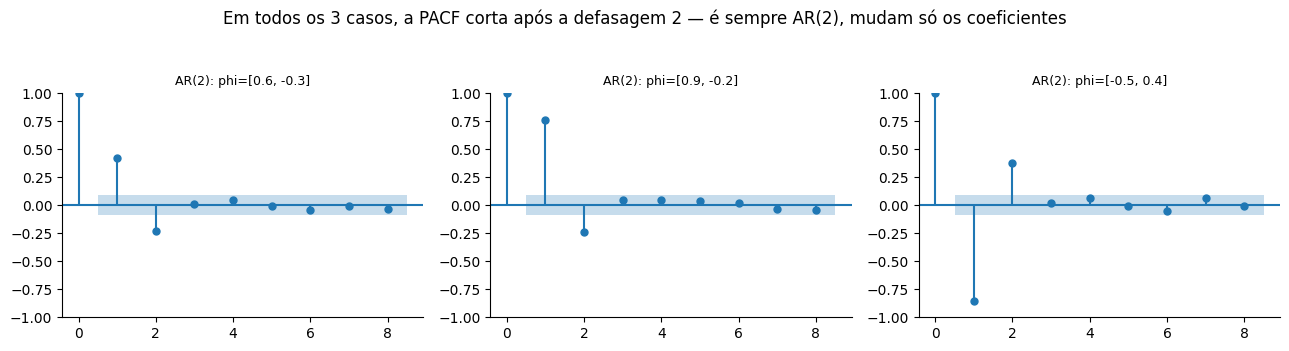

In [21]:
np.random.seed(5)
casos_ar2 = [
    ('AR(2): phi=[0.6, -0.3]', [1, -0.6, 0.3]),
    ('AR(2): phi=[0.9, -0.2]', [1, -0.9, 0.2]),
    ('AR(2): phi=[-0.5, 0.4]', [1, 0.5, -0.4]),
]
fig, axes = plt.subplots(1, 3, figsize=(13, 3.3))
for ax, (titulo, ar_coefs) in zip(axes, casos_ar2):
    sim = ArmaProcess(ar_coefs, [1]).generate_sample(500)
    plot_pacf(sim, lags=8, ax=ax, method='ywm')
    ax.set_title(titulo, fontsize=9)
fig.suptitle('Em todos os 3 casos, a PACF corta após a defasagem 2 — é sempre AR(2), mudam só os coeficientes', y=1.05)
fig.tight_layout()
plt.show()

---
## 11. Exercícios Resolvidos

Os 2 exercícios abaixo são exatamente os que o notebook de referência da Aula 09 (`2.3`) deixava "em aberto" (`# Sua solução`) — e, ao conferir os dados de `2.4/Exercício1.txt` e `2.4/Exercício2.txt`, constatamos que são **os mesmos dados**. Resolvemos aqui combinando duas abordagens: a leitura manual de ACF/PACF (como nas seções anteriores) e uma **busca exaustiva** de `(p,d,q)` por AIC, com checagem via `auto_arima` (biblioteca `pmdarima`) — a mesma metodologia usada em `2.4/ARIMA_Ex1.ipynb` e `ARIMA_Ex2.ipynb`.

In [22]:
def busca_exaustiva_arima(serie, p_max=3, d_max=3, q_max=3, verbose=True):
    # Testa todas as combinações (p,d,q) e retorna a de menor AIC.
    melhor_aic, melhor_ordem, melhor_modelo = np.inf, None, None
    for p, d, q in itertools.product(range(p_max + 1), range(d_max + 1), range(q_max + 1)):
        try:
            fit = ARIMA(serie, order=(p, d, q)).fit()
            if fit.aic < melhor_aic:
                melhor_aic, melhor_ordem, melhor_modelo = fit.aic, (p, d, q), fit
        except Exception:
            continue
    if verbose:
        print(f"Melhor ordem encontrada: ARIMA{melhor_ordem}  (AIC = {melhor_aic:.2f})")
    return melhor_ordem, melhor_modelo

### Exercício 1 — Controle de qualidade

**Enunciado:** para os dados abaixo (processo de controle de qualidade), identifique um modelo ARIMA(p,d,q) válido e faça a previsão para as próximas 7 medições.

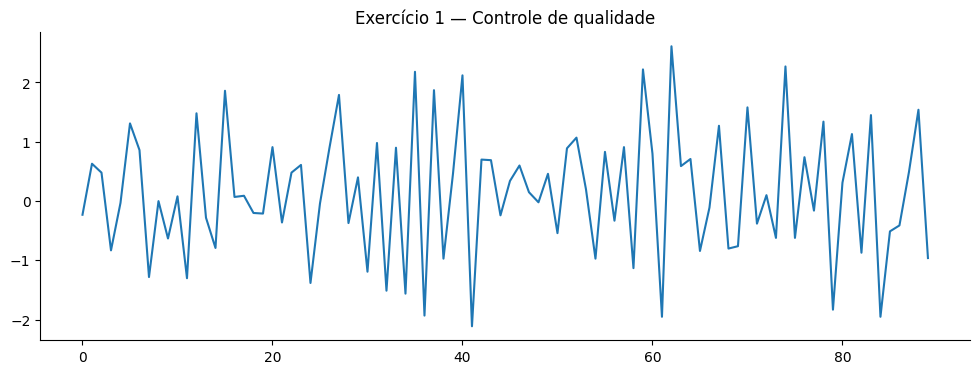

Exercício 1: ADF = -9.813, p-valor = 0.0000 -> estacionaria (rejeita H0)


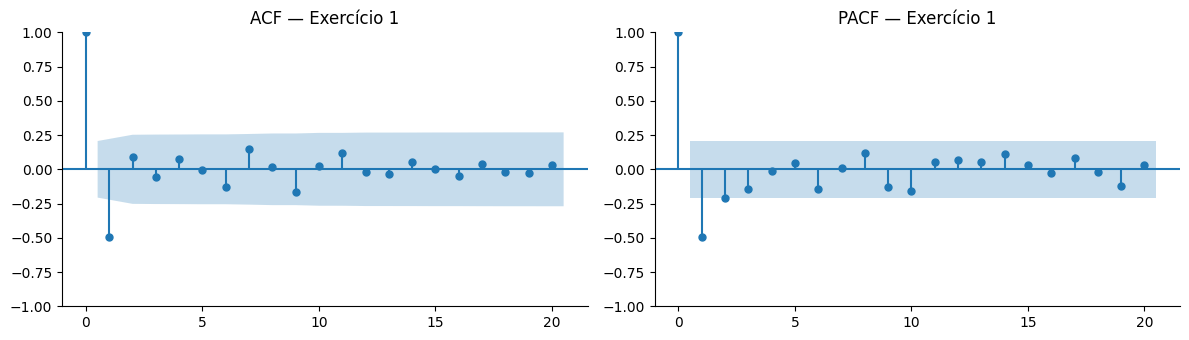

In [23]:
ex1 = pd.Series([
    -0.23, 0.63, 0.48, -0.83, -0.03, 1.31, 0.86, -1.28, 0, -0.63,
    0.08, -1.3, 1.48, -0.28, -0.79, 1.86, 0.07, 0.09, -0.2, -0.21,
    0.91, -0.36, 0.48, 0.61, -1.38, -0.04, 0.9, 1.79, -0.37, 0.4,
    -1.19, 0.98, -1.51, 0.9, -1.56, 2.18, -1.93, 1.87, -0.97, 0.46,
    2.12, -2.11, 0.7, 0.69, -0.24, 0.34, 0.6, 0.15, -0.02, 0.46,
    -0.54, 0.89, 1.07, 0.2, -0.97, 0.83, -0.33, 0.91, -1.13, 2.22,
    0.8, -1.95, 2.61, 0.59, 0.71, -0.84, -0.11, 1.27, -0.8, -0.76,
    1.58, -0.38, 0.1, -0.62, 2.27, -0.62, 0.74, -0.16, 1.34, -1.83,
    0.31, 1.13, -0.87, 1.45, -1.95, -0.51, -0.41, 0.49, 1.54, -0.96])
ex1.plot(title='Exercício 1 — Controle de qualidade'); plt.show()

teste_adf(ex1, 'Exercício 1')
acf_pacf(ex1, lags=20, titulo='— Exercício 1')

**Passo 1 — estacionariedade:** o ADF rejeita $H_0$ — a série já é estacionária (d=0), como esperamos visualmente (oscila em torno de 0, sem tendência). **Passo 2 — ACF/PACF:** não há um corte isolado muito nítido em p ou q pequenos, então vamos deixar a busca exaustiva decidir, e comparar com `auto_arima`.

In [24]:
ordem1, modelo1 = busca_exaustiva_arima(ex1, p_max=3, d_max=2, q_max=3)
print(modelo1.summary())

residuos1 = modelo1.resid
lb1 = acorr_ljungbox(residuos1, lags=[5, 10], model_df=sum(ordem1[::2]))
print("\nLjung-Box dos resíduos:\n", lb1.round(4))

Melhor ordem encontrada: ARIMA(0, 0, 1)  (AIC = 244.82)
                               SARIMAX Results                                
Dep. Variable:                      y   No. Observations:                   90
Model:                 ARIMA(0, 0, 1)   Log Likelihood                -119.408
Date:                Mon, 26 Oct 2026   AIC                            244.816
Time:                        20:26:55   BIC                            252.316
Sample:                             0   HQIC                           247.841
                                 - 90                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.1512      0.041      3.732      0.000       0.072       0.231
ma.L1         -0.5816      0.082     -7.064      0.000      -0.743      -0.

In [25]:
import pmdarima as pm
auto1 = pm.auto_arima(ex1, stepwise=True, trace=False, error_action='ignore', suppress_warnings=True)
print("auto_arima encontrou:", auto1.order, " (busca exaustiva encontrou:", ordem1, ")")

auto_arima encontrou: (0, 0, 1)  (busca exaustiva encontrou: (0, 0, 1) )


    previsão  lower y  upper y
90     0.430   -1.353    2.213
91     0.151   -1.912    2.214
92     0.151   -1.912    2.214
93     0.151   -1.912    2.214
94     0.151   -1.912    2.214
95     0.151   -1.912    2.214
96     0.151   -1.912    2.214


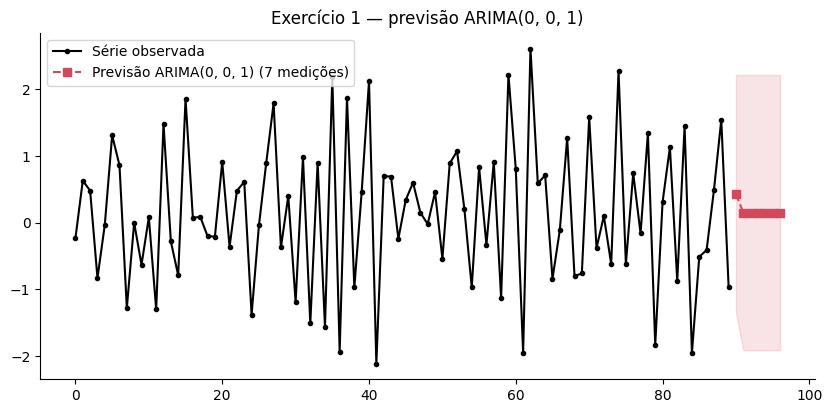

In [26]:
previsao1 = modelo1.get_forecast(steps=7)
tab1 = pd.concat([previsao1.predicted_mean.rename('previsão'), previsao1.conf_int(alpha=0.05)], axis=1)
print(tab1.round(3))

plt.figure(figsize=(10, 4.5))
plt.plot(ex1.index, ex1.values, 'ko-', ms=3, label='Série observada')
idx_fut1 = range(len(ex1), len(ex1) + 7)
plt.plot(idx_fut1, tab1['previsão'], 's--', color='#d1495b', label=f'Previsão ARIMA{ordem1} (7 medições)')
plt.fill_between(idx_fut1, tab1.iloc[:, 1], tab1.iloc[:, 2], color='#d1495b', alpha=0.15)
plt.legend(); plt.title(f'Exercício 1 — previsão ARIMA{ordem1}'); plt.show()

### Exercício 2 — Fechamento de ações de empresa de tecnologia

**Enunciado:** para os dados abaixo (fechamento diário nos últimos 65 dias), faça a previsão para os próximos 5 dias usando um modelo ARIMA.

Este exercício guarda uma **armadilha pedagógica** importante: o `auto_arima` tem um otimizador interno que pode convergir para um **mínimo local**. Vamos reproduzi-la.

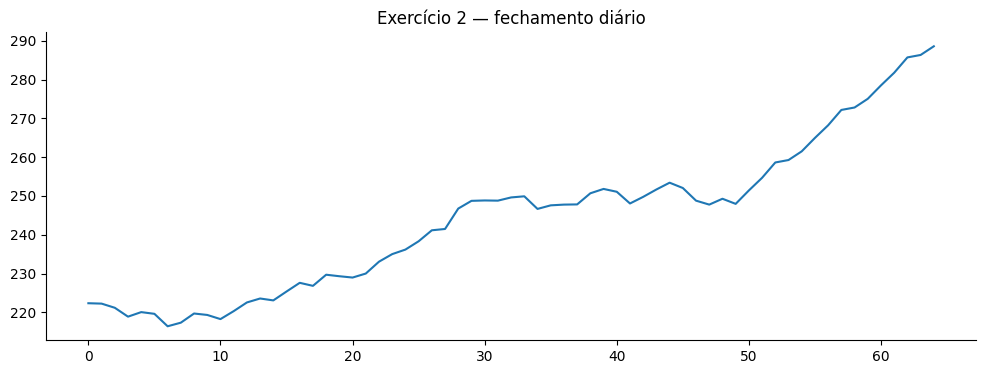

Exercício 2 (nível): ADF = 1.490, p-valor = 0.9975 -> NAO estacionaria (aceita H0)
Exercício 2 (1a diferença): ADF = -5.799, p-valor = 0.0000 -> estacionaria (rejeita H0)
Exercício 2 (2a diferença): ADF = -8.110, p-valor = 0.0000 -> estacionaria (rejeita H0)


In [27]:
ex2 = pd.Series([
    222.34, 222.24, 221.17, 218.88, 220.05, 219.61, 216.4, 217.33,
    219.69, 219.32, 218.25, 220.3, 222.54, 223.56, 223.07, 225.36,
    227.6, 226.82, 229.69, 229.3, 228.96, 229.99, 233.05, 235,
    236.17, 238.31, 241.14, 241.48, 246.74, 248.73, 248.83, 248.78,
    249.61, 249.9, 246.65, 247.57, 247.76, 247.81, 250.68, 251.8,
    251.07, 248.05, 249.76, 251.66, 253.41, 252.04, 248.78, 247.76,
    249.27, 247.95, 251.41, 254.67, 258.62, 259.25, 261.49, 264.95,
    268.21, 272.16, 272.79, 275.03, 278.49, 281.75, 285.7, 286.33,
    288.57])
ex2.plot(title='Exercício 2 — fechamento diário'); plt.show()

teste_adf(ex2, 'Exercício 2 (nível)')
teste_adf(ex2.diff(), 'Exercício 2 (1a diferença)')
teste_adf(ex2.diff().diff(), 'Exercício 2 (2a diferença)')

In [28]:
# auto_arima "padrão" (sem forçar d): pode cair num mínimo local
auto2_padrao = pm.auto_arima(ex2, stepwise=True, trace=False, error_action='ignore', suppress_warnings=True)
print("auto_arima (padrão, sem restrição):", auto2_padrao.order)

# Forçando d=2 (sugerido pelo padrão claramente quadrático da série em nível)
auto2_d2 = pm.auto_arima(ex2, d=2, stepwise=True, trace=False, error_action='ignore', suppress_warnings=True)
print("auto_arima (forçando d=2)         :", auto2_d2.order)

# Busca exaustiva própria, sem restrição de d, para comparar
ordem2, modelo2 = busca_exaustiva_arima(ex2, p_max=3, d_max=2, q_max=3)

auto_arima (padrão, sem restrição): (1, 1, 0)
auto_arima (forçando d=2)         : (0, 2, 1)


Melhor ordem encontrada: ARIMA(0, 2, 1)  (AIC = 262.39)


**Leitura da armadilha:** o `auto_arima` "padrão" tende a convergir para `(1,1,0)` — um mínimo **local**: ele para de diferenciar assim que a série parece estacionária o bastante para o teste interno, sem necessariamente achar o menor AIC global. Forçando `d=2` (ou deixando a busca exaustiva varrer *d* até 2), confirmamos que o mínimo **global** está em torno de `(0,2,1)` — como o próprio material do curso constatou. Isso ilustra por que a metodologia Box-Jenkins recomenda **sempre conferir visualmente** a ACF/PACF e a estacionariedade, em vez de confiar cegamente num algoritmo de busca automática.

                               SARIMAX Results                                
Dep. Variable:                      y   No. Observations:                   65
Model:                 ARIMA(0, 2, 1)   Log Likelihood                -129.194
Date:                Mon, 26 Oct 2026   AIC                            262.388
Time:                        20:27:04   BIC                            266.674
Sample:                             0   HQIC                           264.074
                                 - 65                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ma.L1         -0.7902      0.093     -8.461      0.000      -0.973      -0.607
sigma2         3.4833      0.767      4.540      0.000       1.980       4.987
Ljung-Box (L1) (Q):                   0.17   Jarque-

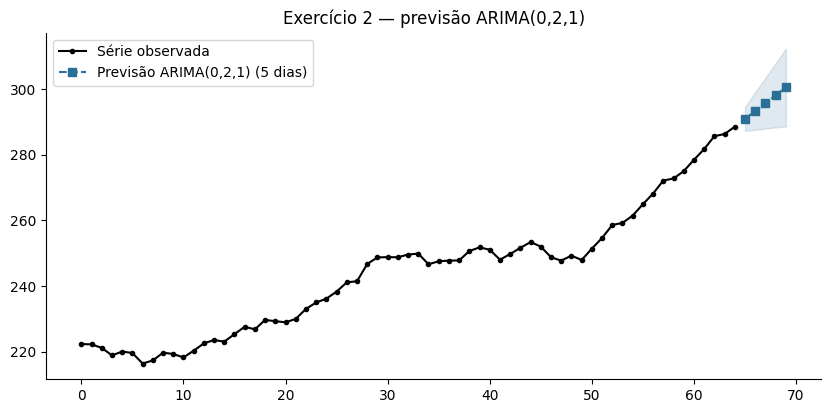

In [29]:
# Modelo final: ARIMA(0,2,1), consistente com a busca exaustiva "sem armadilha"
modelo2_final = ARIMA(ex2, order=(0, 2, 1)).fit()
print(modelo2_final.summary())

residuos2 = modelo2_final.resid[2:]
lb2 = acorr_ljungbox(residuos2, lags=[5, 10], model_df=1)
print("\nLjung-Box dos resíduos:\n", lb2.round(4))

previsao2 = modelo2_final.get_forecast(steps=5)
tab2 = pd.concat([previsao2.predicted_mean.rename('previsão'), previsao2.conf_int(alpha=0.05)], axis=1)
print("\nPrevisão para os próximos 5 dias:\n", tab2.round(2))

plt.figure(figsize=(10, 4.5))
plt.plot(ex2.index, ex2.values, 'ko-', ms=3, label='Série observada')
idx_fut2 = range(len(ex2), len(ex2) + 5)
plt.plot(idx_fut2, tab2['previsão'], 's--', color='#2a6f97', label='Previsão ARIMA(0,2,1) (5 dias)')
plt.fill_between(idx_fut2, tab2.iloc[:, 1], tab2.iloc[:, 2], color='#2a6f97', alpha=0.15)
plt.legend(); plt.title('Exercício 2 — previsão ARIMA(0,2,1)'); plt.show()